# Phân tích và dự đoán bệnh tim mạch

# Phần 1. Khám phá dữ liệu

#### 1.1. Đọc dữ liệu và xem phân bố

In [1]:
import pandas as pd
import matplotlib.pyplot as mpl
import seaborn as sb

dataset_sach = pd.read_csv("cleaned_cardio.csv")

In [3]:
print("Kích thước dữ liệu:", dataset_sach.shape)

print("\nCác cột:")
dataset_sach.columns

Kích thước dữ liệu: (59187, 13)

Các cột:


Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

**Hai nhóm có bao nhiêu người?** Bảng cho biết tỷ lệ phần trăm, còn chiều cao của cột cho biết số người.

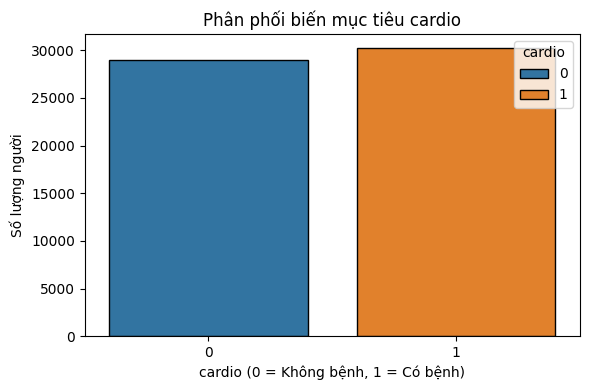

In [4]:
fig, axes = mpl.subplots(1, 1, figsize=(6, 4))

sb.countplot(data=dataset_sach, x="cardio", ax=axes, edgecolor="black", hue='cardio')

axes.set_title("Phân phối biến mục tiêu cardio")
axes.set_xlabel("cardio (0 = Không bệnh, 1 = Có bệnh)")
axes.set_ylabel("Số lượng người")

mpl.tight_layout()
mpl.show()

**Các chỉ số tập trung ở khoảng nào?** Mỗi cột trong histogram đếm số người thuộc một khoảng giá trị.

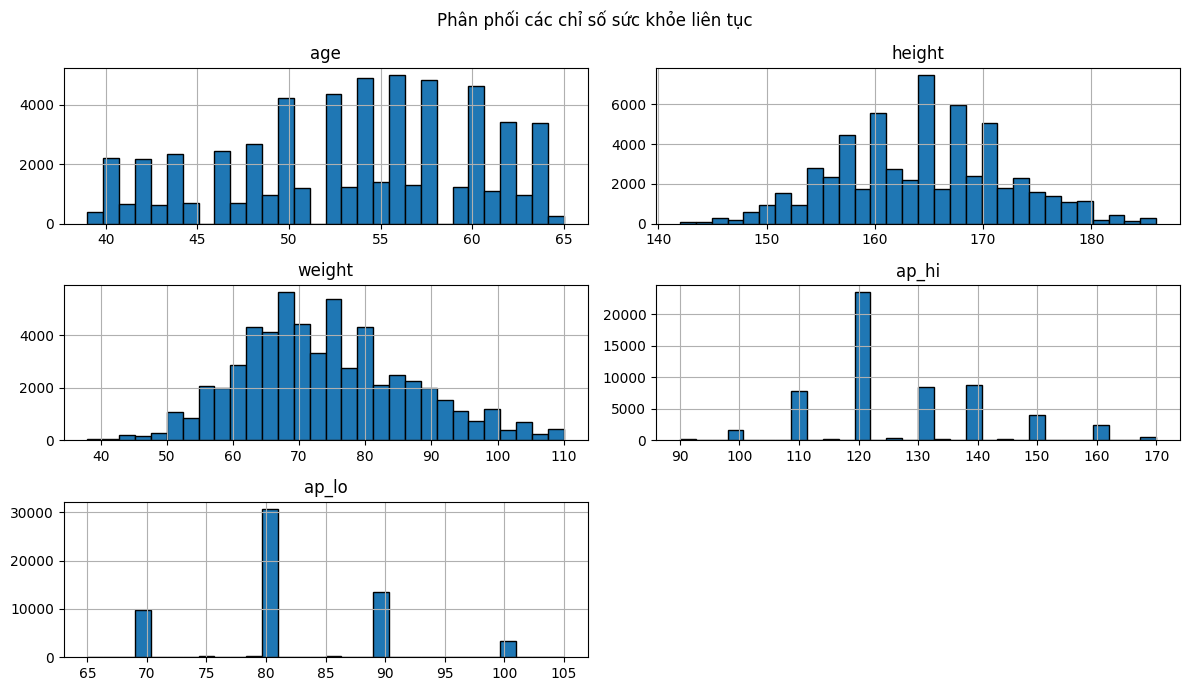

In [5]:
continuous_columns = ["age", "height", "weight", "ap_hi", "ap_lo"]

continuous_data = dataset_sach[continuous_columns]

continuous_data.hist(figsize=(12, 7), bins=30, edgecolor="black")

mpl.suptitle("Phân phối các chỉ số sức khỏe liên tục")

mpl.tight_layout()
mpl.show()

#### 1.2. So sánh người có bệnh và không có bệnh

Đường giữa mỗi hộp là trung vị. So sánh hai đường này để xem chỉ số nào thường cao hơn ở nhóm có bệnh.

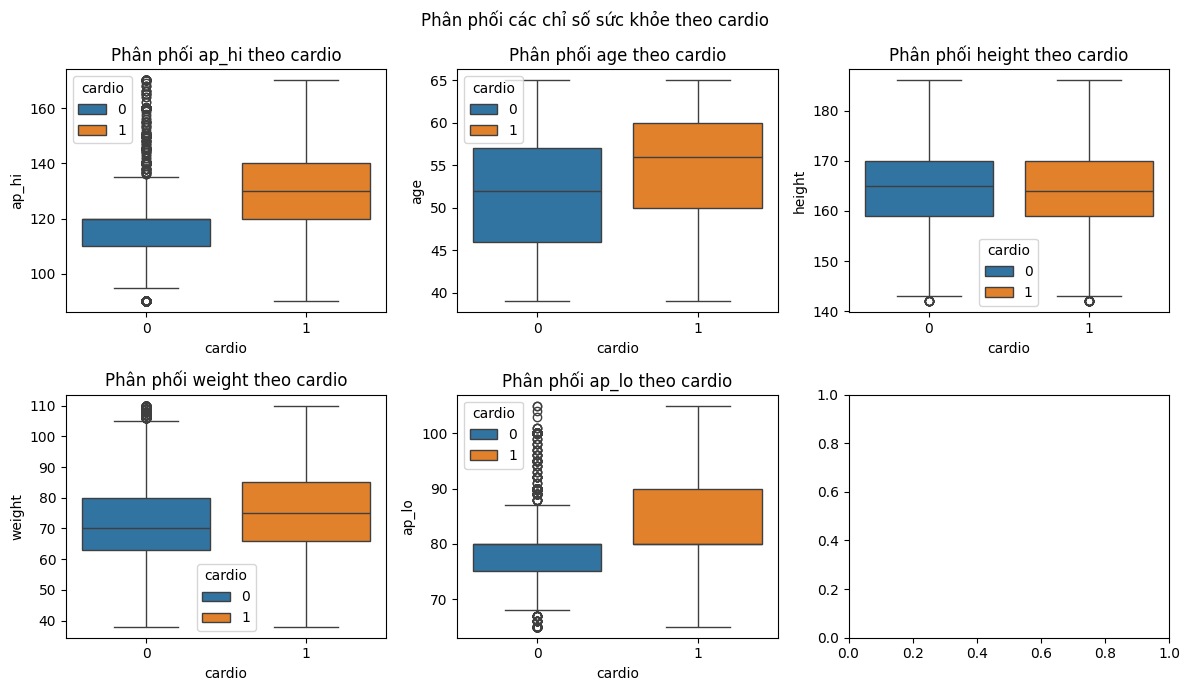

In [6]:
numeric_columns = ["ap_hi", "age", "height", "weight", "ap_lo"]

fig, axes = mpl.subplots(2, 3, figsize=(12, 7))

axes = axes.flatten()

for i in range(0, 5):
    cot = numeric_columns[i]

    sb.boxplot(data=dataset_sach, x="cardio", y=cot, ax=axes[i], hue='cardio')

    axes[i].set_title("Phân phối " + cot + " theo cardio")
    axes[i].set_xlabel("cardio")
    axes[i].set_ylabel(cot)

mpl.suptitle("Phân phối các chỉ số sức khỏe theo cardio")

mpl.tight_layout()
mpl.show()

**Các đặc điểm còn lại.** Biểu đồ này đếm số người. Khi hai nhóm có quy mô khác nhau, cần so sánh tỷ lệ trước khi kết luận nhóm nào thường mắc bệnh hơn.

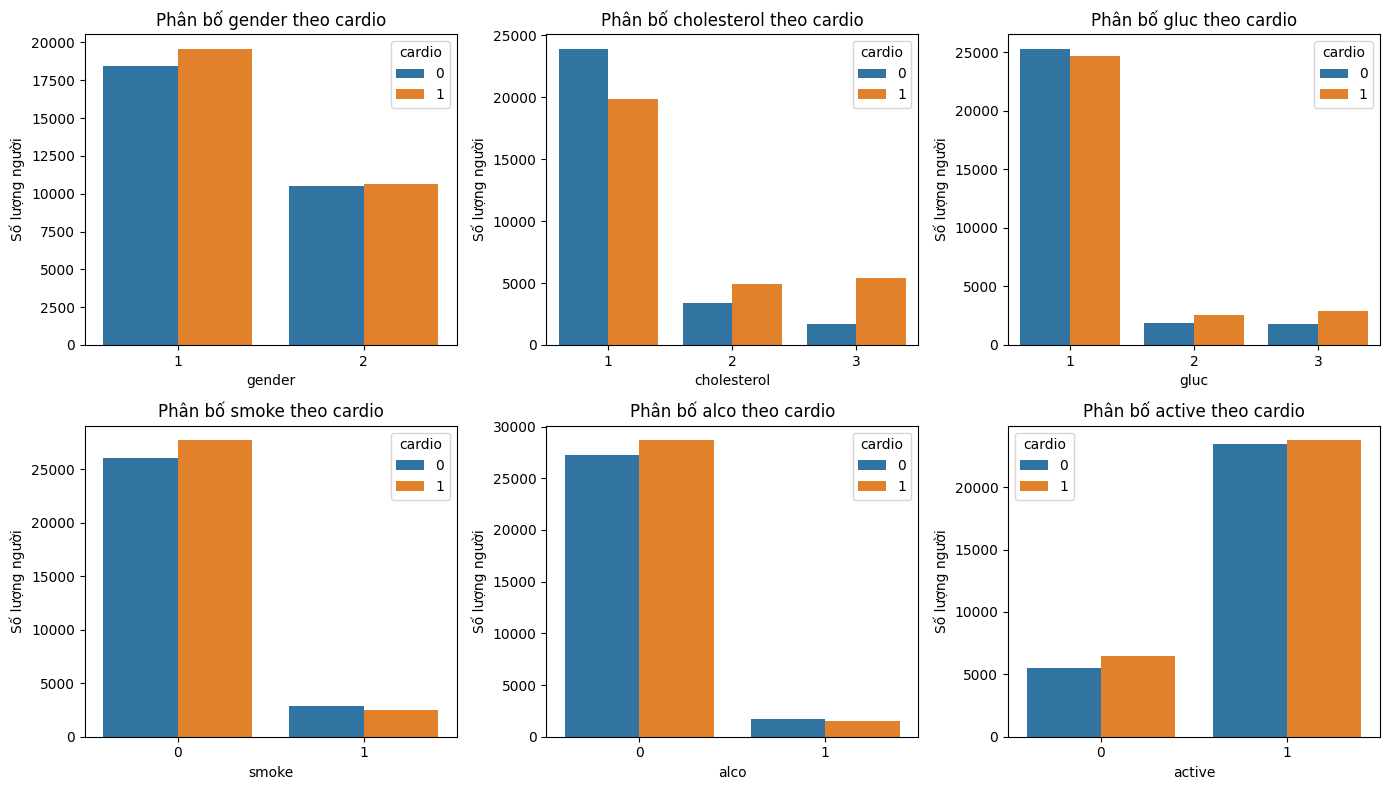

In [7]:
category_columns = ["gender", "cholesterol", "gluc", "smoke", "alco", "active"]

fig, axes = mpl.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i in range(0, 6):
    column_name = category_columns[i]

    sb.countplot(data=dataset_sach, x=column_name, hue="cardio", ax=axes[i])

    chart_title = "Phân bố " + column_name + " theo cardio"
    axes[i].set_title(chart_title)
    axes[i].set_xlabel(column_name)
    axes[i].set_ylabel("Số lượng người")

mpl.tight_layout()
mpl.show()

#### 1.3. Chỉ số nào có tương quan với nhãn bệnh?

Hệ số dương cho biết hai biến có xu hướng tăng cùng nhau. Bỏ qua đường chéo vì mỗi biến được so với chính nó.

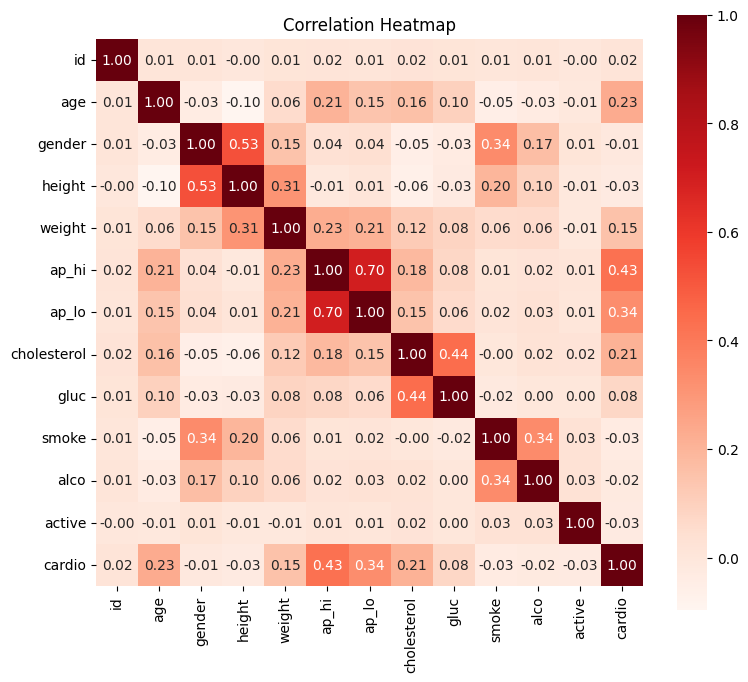

In [8]:
mpl.figure(figsize=(8, 8))

sb.heatmap(dataset_sach.corr(), annot=True, fmt=".2f", cmap="Reds", square=True, cbar_kws={"shrink": 0.8})
mpl.title("Correlation Heatmap")
mpl.tight_layout()
mpl.show()

In [9]:
cardio_correlation = dataset_sach.corr()["cardio"]
cardio_correlation = cardio_correlation.sort_values(ascending=False)

cardio_correlation

cardio         1.000000
ap_hi          0.429538
ap_lo          0.335058
age            0.231855
cholesterol    0.209871
weight         0.154334
gluc           0.075879
id             0.018645
gender        -0.012463
alco          -0.019457
height        -0.026492
active        -0.027960
smoke         -0.030206
Name: cardio, dtype: float64

**Nhận xét từ kết quả đã lưu.** Huyết áp tâm thu (`ap_hi`, 0,43) và tâm trương (`ap_lo`, 0,34) có tương quan dương cao nhất với nhãn bệnh trong các chỉ số được xét. Đây là mối liên hệ quan sát được trong bộ dữ liệu.

In [10]:
dataset_sach = dataset_sach.drop(columns=["id", "active"])
dataset_sach.to_csv("File_train.csv", index=False)

print("Đã lưu file File_train.csv")
print("Kích thước:", dataset_sach.shape[0], "hàng,", dataset_sach.shape[1], "cột")

Đã lưu file File_train.csv
Kích thước: 59187 hàng, 11 cột
